In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

# О датасете


In [63]:
#!/bin/bash
curl -L -o titanic/titanic-dataset.zip\
  https://www.kaggle.com/api/v1/datasets/download/yasserh/titanic-dataset
unzip titanic/titanic-dataset.zip

SyntaxError: invalid syntax (2030439000.py, line 2)

In [6]:
import os 
DATA_PATH=os.path.join("titanic", "Titanic-Dataset.csv")
data = pd.read_csv(DATA_PATH, sep=",")
print(data.shape)
print("Типы признаков:")
print(data.dtypes.to_string())

print("\nПропуски:", int(data.isna().sum().sum()))
print("Полных дубликатов строк:", int(data.duplicated().sum()))

constant_columns = [c for c in data.columns if data[c].nunique() == 1]
print("Константные признаки:", constant_columns)

print("\nОписательные статистики:")
data.head()

(891, 12)
Типы признаков:
PassengerId      int64
Survived         int64
Pclass           int64
Name               str
Sex                str
Age            float64
SibSp            int64
Parch            int64
Ticket             str
Fare           float64
Cabin              str
Embarked           str

Пропуски: 866
Полных дубликатов строк: 0
Константные признаки: []

Описательные статистики:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Мы видим, что у нас есть 11 признаков. Из них 6 числовых и 5 строковых. В данных есть пропуски. Дубликатов и константных признаков нет. Признаки `PassengerId` и `Name` можно исключить. Они приведут к бессмысленному запоминанию объекта. Строковые признаки нужно заменить на числовые через one-hot encoder.
# Изучение целевого признака

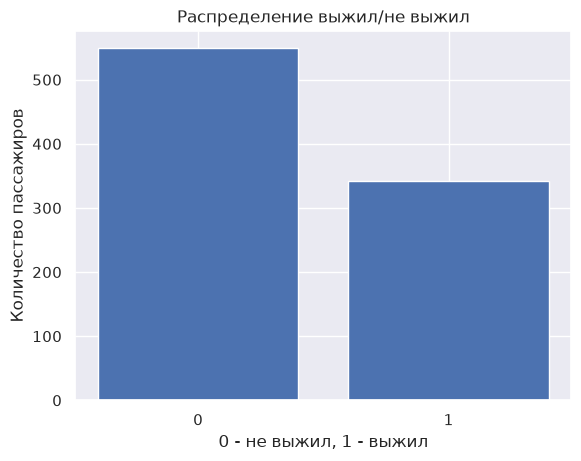

Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


In [85]:
plt.figure()
counts = data['Survived'].value_counts().sort_index()
plt.bar(counts.index.astype(str), counts) 
plt.title('Распределение выжил/не выжил')
plt.xlabel("0 - не выжил, 1 - выжил")
plt.ylabel("Количество пассажиров")
plt.show()
print(data['Survived'].value_counts(normalize=True).mul(100).round(2))

Мы можем увидеть, что число невыживших больше, чем выживших. Выживших всего 38.38%. Значит accuracy не будет хорошей метрикой.
# Распределение признаков
Посмотрим на распределение числовых признаков.

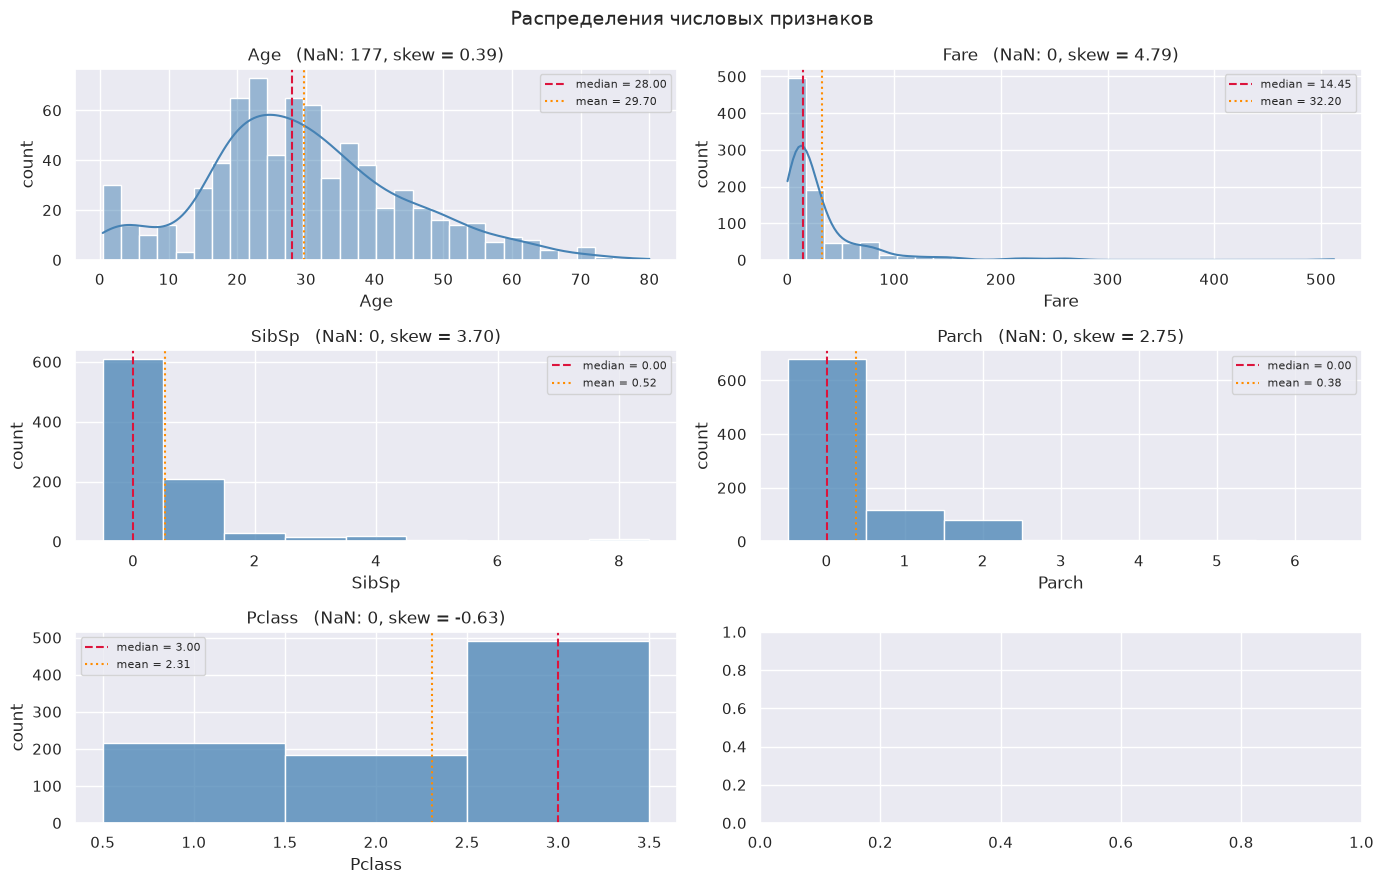

In [86]:
NUM_FEATURES = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass']

fig, axes = plt.subplots(3, 2, figsize=(14, 9))
for ax, col in zip(axes.ravel(), NUM_FEATURES):
    s = data[col].dropna()
    discrete = s.nunique() <= 15

    sns.histplot(
        x=s,
        bins=s.nunique() if discrete else 30,
        discrete=discrete,
        kde=not discrete,
        color='steelblue',
        edgecolor='white',
        ax=ax,
    )
    ax.axvline(s.median(), color='crimson', ls='--', lw=1.5,
               label=f'median = {s.median():.2f}')
    ax.axvline(s.mean(), color='darkorange', ls=':', lw=1.5,
               label=f'mean = {s.mean():.2f}')

    ax.set_title(f'{col}   (NaN: {data[col].isna().sum()}, '
                 f'skew = {s.skew():.2f})')
    ax.set_xlabel(col)
    ax.set_ylabel('count')
    ax.legend(fontsize=8)

fig.suptitle('Распределения числовых признаков', fontsize=14)
fig.tight_layout()
plt.show()


Мы можем увидеть, что признаки `SibSp`, `Parch`, `Fare` сильно скошены вправо.

In [87]:
num = data.drop(columns=['Survived', 'Pclass']).select_dtypes('number')
corr = num.corrwith(data['Survived'], method='pearson').sort_values()
print(corr)
dummies = pd.get_dummies(data[['Sex', 'Pclass', 'Embarked']], drop_first=False)
dummies.corrwith(data['Survived']).sort_values().round(3)

Age           -0.077221
SibSp         -0.035322
PassengerId   -0.005007
Parch          0.081629
Fare           0.257307
dtype: float64


Sex_male     -0.543
Pclass       -0.338
Embarked_S   -0.156
Embarked_Q    0.004
Embarked_C    0.168
Sex_female    0.543
dtype: float64

По корреляциям можно предположить, что самыми важными признаками являются `Sex`, `Pclass`, `Fare`.

## Выводы по предварительному анализу
1. Признаки `PassengerId` и `Name` мы исключаем из наборы признаков, так как они приведут к ненужному запоминанию.
2. Невыживших пассажиров сильно больше, чем выживших(61.62% не выжило). Значит на `Accuracy` ориентироваться нельзя.
3. В данных есть пропуски и строковые признаки. Пропуски в числовых признаках можно заменить медианой из-за скошенности некоторых признаков. Пропуски в строковых признаках можно заменить модой. Некоторые строковые признаки можно преобразовать в числовые через `one-hot encoding`.
4. Самыми важными признаками являются `Sex`, `Pclass`, `Fare`.

# Подготовка данных и выборка
Уберем признаки `PassengerId`, `Name`, `Ticket` из выборки. У строкового признака `Cabin` оставим только палубу, она скорее всего влияет на выживаемость. К остальным строковым признакам применим `one-hot` кодирование. Пропуски в числовых признаках будем заполнять медианой, а в строковых модойh кроме `Cabin`, там пустые значения мы будет помечать `Unknown`, так как зачастую значения `Cabin` неизвестны и отсутствие каюты умышленно. `Pclass` оставим в категориальных признаках.

In [7]:
print(data['Cabin'].fillna("Unknown").value_counts())

Cabin
Unknown        687
G6               4
C23 C25 C27      4
B96 B98          4
F33              3
              ... 
E17              1
A24              1
C50              1
B42              1
C148             1
Name: count, Length: 148, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder 
from sklearn.base import BaseEstimator, TransformerMixin
RANDOM_STATE=42
X = data.drop(columns=['Survived'])
y = data['Survived']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
cat_cols = ['Sex', 'Pclass', 'Embarked']


class CabinDeckExtractor(BaseEstimator, TransformerMixin):
    """Replaces the raw Cabin column with its deck letter (first char)."""
    def __init__(self, col='Cabin', missing='Unknown'):
        self.col = col
        self.missing = missing

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        deck = X[self.col].str[0].fillna(self.missing)
        return deck.to_frame(name='Deck')
    def get_feature_names_out(self, input_features=None):
        return np.asarray(['Deck'], dtype=object)

preprocess = ColumnTransformer([
    ('num', Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median"))
        ]
            ), num_cols),
    ('cat', Pipeline(
        [
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown='ignore'))
            ]), cat_cols),
    ('Cabin', Pipeline(
       [
          ("get_deck", CabinDeckExtractor()),
          ("onehot", OneHotEncoder(handle_unknown="ignore"))

       ]) , ['Cabin']
    )
])
X_ready = preprocess.fit_transform(X_train)
print(X_train.shape)
print(X_ready.shape)

(712, 11)
(712, 21)


# Baseline


In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

dummy = Pipeline(
    [
    ("preprocess", preprocess),
("dummy", DummyClassifier(strategy="most_frequent"))
    ]
    )

dummy.fit(X_train, y_train)
y_pred= dummy.predict(X_test)

print("Accuracy:          ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_test, y_pred, zero_division=0))
print("F1:        ", f1_score(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy:           0.6145251396648045
Precision:  0.0
Recall:     0.0
F1:         0.0
Confusion matrix:
[[110   0]
 [ 69   0]]


# Decision tree

In [20]:
# Подбор параметров
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

decision_tree= Pipeline(
    [("preprocess", preprocess),
      ("tree",
       DecisionTreeClassifier(random_state=RANDOM_STATE)
    )]
)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    decision_tree,
    {"tree__max_depth": [3, 6, 8, 10, 20, 30],
     "tree__min_samples_leaf": [4, 8, 12, 16]},
    scoring="f1", cv=cv, n_jobs=-1,
)
grid.fit(X_train, y_train)
print(grid.best_params_, grid.best_score_)

{'tree__max_depth': 10, 'tree__min_samples_leaf': 4} 0.7279228948917953


In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

decision_tree = grid.best_estimator_
decision_tree.fit(X_train, y_train)
y_pred = decision_tree.predict(X_train)
# На тренировочных данных
print("Accuracy:          ", accuracy_score(y_train, y_pred))
print("Precision: ", precision_score(y_train, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_train, y_pred, zero_division=0))
print("F1:        ", f1_score(y_train, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_train, y_pred))

Accuracy:           0.8918539325842697
Precision:  0.9117647058823529
Recall:     0.7948717948717948
F1:         0.8493150684931506
Confusion matrix:
[[418  21]
 [ 56 217]]


In [23]:
# На тестовых данных
y_pred = decision_tree.predict(X_test)
print("Accuracy:          ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_test, y_pred, zero_division=0))
print("F1:        ", f1_score(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy:           0.7877094972067039
Precision:  0.7627118644067796
Recall:     0.6521739130434783
F1:         0.703125
Confusion matrix:
[[96 14]
 [24 45]]


## Анализ ошибок

In [24]:
import numpy as np
import pandas as pd

proba = decision_tree.predict_proba(X_test)[:, 1]      # P(Survived=1)
y_pred = decision_tree.predict(X_test)

err = data.loc[X_test.index].copy()  
err["pred"] = y_pred
err["proba"] = proba.round(3)
err["error_type"] = np.select(
    [(err.Survived == 1) & (err.pred == 0), (err.Survived == 0) & (err.pred == 1)],
    ["FN", "FP"], default="ok",
)
counts = pd.crosstab(
    [err["Sex"], err["Pclass"]],
    err["error_type"],
    margins=True, margins_name="Всего",
)
counts["ошибок, %"] = (
    (counts["FP"] + counts["FN"]) / counts["Всего"] * 100
).round(1)
a = err[err["error_type"] != "ok"]
fare_med = a.groupby(["Sex", "Pclass"])["Fare"].median().rename("Fare, медиана")
counts = counts.join(fare_med)
errors = err[err.error_type != "ok"]

# возрастные группы
err["AgeBin"] = pd.cut(err["Age"], [0, 10, 18, 35, 60, 80])
a = err[err["error_type"] != "ok"]
fare_med = a.groupby(["AgeBin"])["Fare"].median().rename("Fare, медиана")

age_counts = pd.crosstab(
    err["AgeBin"],
    err["error_type"],
    margins=True, margins_name="Всего",
)
age_counts = age_counts.join(fare_med)
age_counts["ошибок, %"] = (
    (age_counts["FP"] + age_counts["FN"]) / age_counts["Всего"] * 100
).round(1)
print(counts)
print(age_counts)

               FN  FP   ok  Всего  ошибок, %  Fare, медиана
Sex    Pclass                                              
female 1        1   1   13     15       13.3       89.05000
       2        0   1   17     18        5.6       13.00000
       3        4   3   21     28       25.0        7.92500
male   1        7   6   17     30       43.3       61.17500
       2        3   0   13     16       18.8       13.00000
       3        9   3   60     72       16.7        8.00415
Всего          24  14  141    179       21.2            NaN
          FN  FP   ok  Всего  Fare, медиана  ошибок, %
AgeBin                                                
(0, 10]    4   1    7     12        20.5250       41.7
(10, 18]   1   2   16     19        11.2417       15.8
(18, 35]  10   3   61     74         7.9250       17.6
(35, 60]   5   5   18     28        70.1875       35.7
(60, 80]   1   0    5      6        10.5000       16.7
Всего     21  11  107    139            NaN       23.0


Чаще всего модель ошибается на мужчинах 1 класса и женщинах 3 класса. По возрасту чаще всего ошибается на несовершеннолетних.

# Feature importance
Я намеренно объединил обратно производные признаки(признаки, которые получились от категориальных из-за one-hot кодирования). Это связано с тем, что модель может строить зависимость от целого признака только проверив его на одно из его значений. Важность может быть размазана по значениям признака.

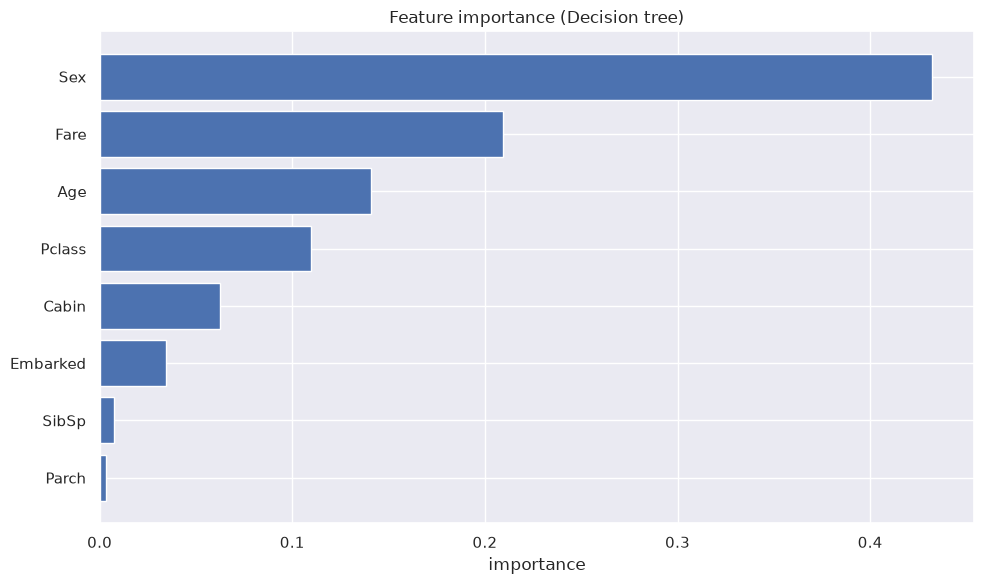

In [25]:
# Feature importance
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Cabin"]

prep = decision_tree["preprocess"]
tree = decision_tree["tree"]

names = prep.get_feature_names_out()
imp = pd.Series(tree.feature_importances_, index=names)
imp.sort_values(ascending=False).round(4)

RAW = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Cabin", "Deck"]
ALIAS = {"Deck": "Cabin"}             

def source(name):
    base = name.split("__", 1)[1]  
    for c in RAW:
        if base == c or base.startswith(c + "_"):
            return ALIAS.get(c, c)
    return base

grouped = imp.groupby(imp.index.map(source)).sum().sort_values(ascending=True)
grouped.round(4)

plt.figure(figsize=(10, 6))
plt.barh(grouped.index, grouped.values)
plt.title("Feature importance (Decision tree)")
plt.xlabel("importance")
plt.tight_layout()


Модель выяснила, что самыми важными признаками являются пол, стоимость проезда и возраст. Этот результат отличается от предварительного анализа тем, что там возраст не был важным признаком. Возможно это связано с тем, что между возрастом и выживаемостью есть нелинейная зависимость, а коррелляция показывает только линейную. Возможно еще, что у `Age` больше уникальных значений, а значит дерево решений может создать больше разветвлений на основе возраста, что увеличивает общее изменение примеси.

Ранее модель ошибалась на женщинах 3 класса. Это скорее всего связано с тем, что фактор пола важнее фактора класса.

## Выводы
1. У модели есть признаки переобучения, так как на тренировочной выборке F1 был на 0.15 больше, чем на тестовой.
2. Можно говорить о том, что модель делает точные предсказания выживания пассажира, но не находит всех выживших.
3. Модель выяснила, что самыми важными признаками являются пол, стоимость проезда и возраст, что отличается от предварительного анализа, где возраст не был решающим фактором.

# Случайный лес

In [ ]:
# Подбор параметров
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

random_forest = Pipeline(
    [("preprocess", preprocess),
      ("tree",
       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)
    )]
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    random_forest,
    {"tree__max_depth": [4, 6, 8, 10],
     "tree__min_samples_leaf": [8, 16, 32],
     "tree__n_estimators": [100, 200, 300, 500]},
    scoring="f1", cv=cv, n_jobs=-1, verbose=2
)
grid.fit(X_train, y_train)
print(grid.best_params_, grid.best_score_)

Fitting 5 folds for each of 80 candidates, totalling 400 fits
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=100; total time=   0.3s[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=100; total time=   0.3s

[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=100; total time=   0.4s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=100; total time=   0.4s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=200; total time=   0.7s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=200; total time=   0.7s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=200; total time=   0.7s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_estimators=200; total time=   0.7s
[CV] END tree__max_depth=4, tree__min_samples_leaf=2, tree__n_est

/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

[CV] END tree__max_depth=4, tree__min_samples_leaf=8, tree__n_estimators=300; total time=   1.0s
[CV] END tree__max_depth=4, tree__min_samples_leaf=16, tree__n_estimators=100; total time=   0.4s
[CV] END tree__max_depth=4, tree__min_samples_leaf=8, tree__n_estimators=300; total time=   1.0s
[CV] END tree__max_depth=4, tree__min_samples_leaf=8, tree__n_estimators=300; total time=   1.0s
[CV] END tree__max_depth=4, tree__min_samples_leaf=16, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=4, tree__min_samples_leaf=16, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=4, tree__min_samples_leaf=16, tree__n_estimators=200; total time=   0.8s
[CV] END tree__max_depth=4, tree__min_samples_leaf=8, tree__n_estimators=500; total time=   1.6s
[CV] END tree__max_depth=4, tree__min_samples_leaf=8, tree__n_estimators=500; total time=   1.6s
[CV] END tree__max_depth=4, tree__min_samples_leaf=8, tree__n_estimators=500; total time=   1.6s
[CV] END tree__max_depth=4

/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

[CV] END tree__max_depth=6, tree__min_samples_leaf=4, tree__n_estimators=300; total time=   1.0s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=6, tree__min_samples_leaf=4, tree__n_estimators=300; total time=   1.0s
[CV] END tree__max_depth=6, tree__min_samples_leaf=4, tree__n_estimators=300; total time=   1.1s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=200; total time=   0.8s
[CV] END tree__max_depth=6, tree__min_samples_leaf=4, tree__n_estimators=500; total time=   1.5s
[CV] END tree__max_depth=6, tree__min_samples_leaf=4, tree__n_estimators=500; total time=   1.6s
[CV] END tree__max_depth=6, tree__min_samples_leaf=4, tree__n_estimators=500; total time=   1.6s
[CV] END tree__max_depth=6, tr

/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/timur/Documents/Programming/ML_MAI/ml_course_mai/.venv/lib/python3.14/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread

[CV] END tree__max_depth=10, tree__min_samples_leaf=2, tree__n_estimators=200; total time=   0.8s
[CV] END tree__max_depth=8, tree__min_samples_leaf=32, tree__n_estimators=500; total time=   1.7s
[CV] END tree__max_depth=8, tree__min_samples_leaf=32, tree__n_estimators=500; total time=   1.7s
[CV] END tree__max_depth=10, tree__min_samples_leaf=2, tree__n_estimators=300; total time=   1.1s
[CV] END tree__max_depth=10, tree__min_samples_leaf=2, tree__n_estimators=300; total time=   1.1s
[CV] END tree__max_depth=10, tree__min_samples_leaf=4, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=10, tree__min_samples_leaf=4, tree__n_estimators=100; total time=   0.5s
[CV] END tree__max_depth=10, tree__min_samples_leaf=2, tree__n_estimators=300; total time=   1.1s
[CV] END tree__max_depth=10, tree__min_samples_leaf=4, tree__n_estimators=100; total time=   0.4s
[CV] END tree__max_depth=10, tree__min_samples_leaf=4, tree__n_estimators=100; total time=   0.4s
[CV] END tree__max_d

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

random_forest = Pipeline(
    [("preprocess", preprocess),
      ("tree",
       RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, max_depth=8, min_samples_leaf=8, n_estimators=300)
    )]
)
random_forest.fit(X_train, y_train)
y_pred = random_forest.predict(X_train)
# На тренировочных данных
print("Accuracy:          ", accuracy_score(y_train, y_pred))
print("Precision: ", precision_score(y_train, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_train, y_pred, zero_division=0))
print("F1:        ", f1_score(y_train, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_train, y_pred))

Accuracy:           0.851123595505618
Precision:  0.8812785388127854
Recall:     0.706959706959707
F1:         0.7845528455284553
Confusion matrix:
[[413  26]
 [ 80 193]]


In [39]:
#На тестовых данных
y_pred = random_forest.predict(X_test)
print("Accuracy:          ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_test, y_pred, zero_division=0))
print("F1:        ", f1_score(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy:           0.8156424581005587
Precision:  0.875
Recall:     0.6086956521739131
F1:         0.717948717948718
Confusion matrix:
[[104   6]
 [ 27  42]]


## Про результаты модели
Если модель предсказала, что пассажир выжил, ей можно верить, но она плохо находит всех выживших.

## Feature importance
Аналогично с деревом решений объединил категориальные признаки обратно.

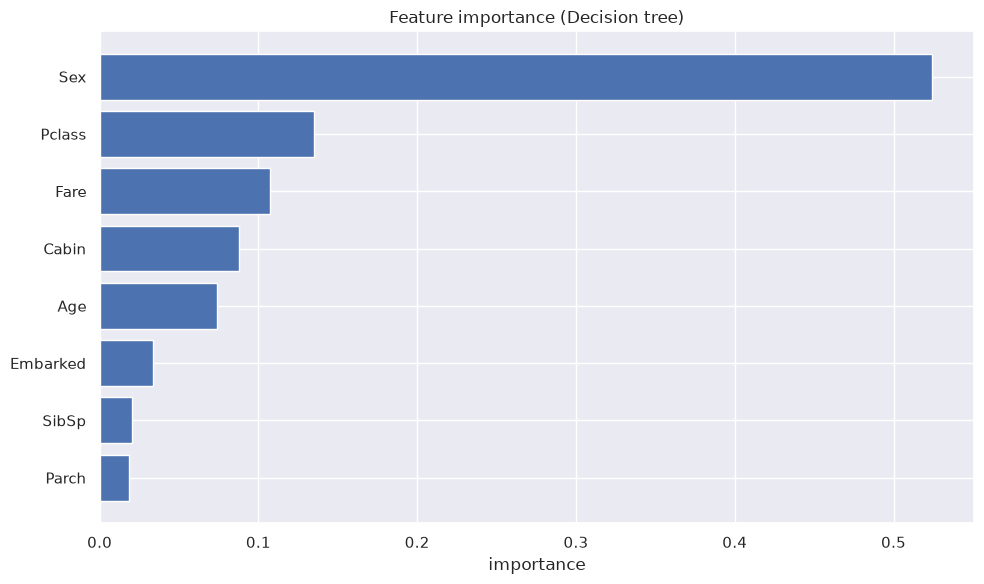

In [46]:
# Feature importance
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Cabin"]

prep = random_forest["preprocess"]
tree = random_forest["tree"]

names = prep.get_feature_names_out()
imp = pd.Series(tree.feature_importances_, index=names)
imp.sort_values(ascending=False).round(4)

RAW = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Cabin", "Deck"]
ALIAS = {"Deck": "Cabin"}             

def source(name):
    base = name.split("__", 1)[1]  
    for c in RAW:
        if base == c or base.startswith(c + "_"):
            return ALIAS.get(c, c)
    return base

grouped = imp.groupby(imp.index.map(source)).sum().sort_values(ascending=True)
grouped.round(4)

plt.figure(figsize=(10, 6))
plt.barh(grouped.index, grouped.values)
plt.title("Feature importance (Decision tree)")
plt.xlabel("importance")
plt.tight_layout()

Модель выявила, что решающими признаками являются пол, класс и стоимость тарифа. Этот результат сходится с предварительным анализом и расходится с результатом одного дерева. Random Forest более правдоподобно оценивает важность признаков, так как там строится несколько деревьев, а feature importance усредняется по ним. С деревом решений нам скорее всего просто повезло. 

## Выводы
1. Модель не переобучена, F1 score на тренировочной выборке больше, чем на тестовой, но не критично.
2. Модель точно оценивает выживаемость пассажира(точнее, чем одно дерево решений), но плохо выявляет все случаи выживания.
3. Случайный лес немного лучше по F1 score, чем дерево решений.
4. Случайный лес расставил важность признаков не так, как дерево решений. Возможно на одно дерево решений повлияли экстремальные случаи, влияние которых усредняется в случайном лесе.

# Gradient boosting

In [40]:
# Подбор параметров
from sklearn.ensemble import GradientBoostingClassifier 
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

gradient_boosting = Pipeline(
    [("preprocess", preprocess),
      ("tree",
       GradientBoostingClassifier(random_state=RANDOM_STATE, learning_rate=0.05)
    )]
)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    gradient_boosting,
    {"tree__max_depth": [6, 8, 10],
     "tree__min_samples_leaf": [8, 16, 32],
     "tree__n_estimators": [100, 300, 500]},
    scoring="f1", cv=cv, n_jobs=-1, verbose=2
)
grid.fit(X_train, y_train)
print(grid.best_params_, grid.best_score_)

Fitting 10 folds for each of 27 candidates, totalling 270 fits
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.3s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_estimators=100; total time=   0.4s
[CV] END tree__max_depth=6, tree__min_samples_leaf=8, tree__n_es

In [43]:
# Тренировочные данные
from sklearn.metrics import (
    accuracy_score,
    precision_score, recall_score, f1_score,
    confusion_matrix
)

gradient_boosting = Pipeline(
    [("preprocess", preprocess),
      ("tree",
       GradientBoostingClassifier(random_state=RANDOM_STATE, learning_rate=0.05, max_depth=10, min_samples_leaf=32, n_estimators=100)
    )]
)
gradient_boosting.fit(X_train, y_train)
y_pred = gradient_boosting.predict(X_train)
# На тренировочных данных
print("Accuracy:          ", accuracy_score(y_train, y_pred))
print("Precision: ", precision_score(y_train, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_train, y_pred, zero_division=0))
print("F1:        ", f1_score(y_train, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_train, y_pred))

Accuracy:           0.8862359550561798
Precision:  0.9
Recall:     0.7912087912087912
F1:         0.8421052631578947
Confusion matrix:
[[415  24]
 [ 57 216]]


In [44]:
#На тестовых данных
y_pred = gradient_boosting.predict(X_test)
print("Accuracy:          ", accuracy_score(y_test, y_pred))
print("Precision: ", precision_score(y_test, y_pred, zero_division=0))
print("Recall:    ", recall_score(y_test, y_pred, zero_division=0))
print("F1:        ", f1_score(y_test, y_pred, zero_division=0))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy:           0.7877094972067039
Precision:  0.7627118644067796
Recall:     0.6521739130434783
F1:         0.703125
Confusion matrix:
[[96 14]
 [24 45]]


## Оценка результатов
Gradient boosting дал меньшую F1 метрику чем случайный лес. Модель получилась менее точной, чем случайный лес, но получила больший recall. Это значит, что модель лучше заучила экстремальные случаи, но хуже выучила базовые случаи.

## Feature importance

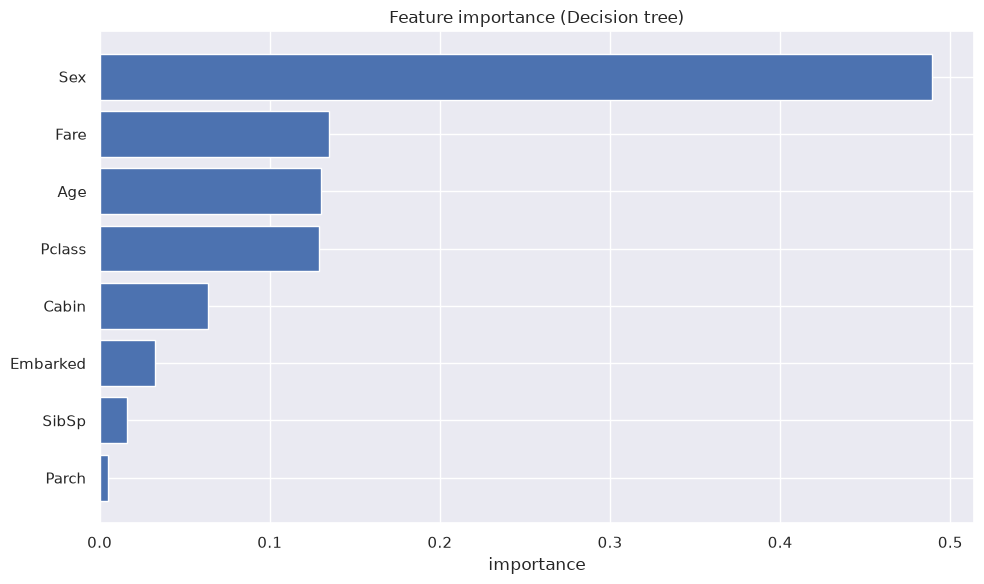

In [45]:
# Feature importance
cols = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Cabin"]

prep = gradient_boosting["preprocess"]
tree = gradient_boosting["tree"]

names = prep.get_feature_names_out()
imp = pd.Series(tree.feature_importances_, index=names)
imp.sort_values(ascending=False).round(4)

RAW = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked", "Cabin", "Deck"]
ALIAS = {"Deck": "Cabin"}             

def source(name):
    base = name.split("__", 1)[1]  
    for c in RAW:
        if base == c or base.startswith(c + "_"):
            return ALIAS.get(c, c)
    return base

grouped = imp.groupby(imp.index.map(source)).sum().sort_values(ascending=True)
grouped.round(4)

plt.figure(figsize=(10, 6))
plt.barh(grouped.index, grouped.values)
plt.title("Feature importance (Decision tree)")
plt.xlabel("importance")
plt.tight_layout()

Модель ранжировала 3 самых важных признака так же как и дерево решений. Важность признака пола у gradient boosting выше, чем у дерева решений. 

## Выводы
1. Gradient boosting склонна выдавать лишние true positive, что говорит о большем recall, но низком precision.
2. Gradient boosting склонен делать много оценок по первому по важности признаку(сильно больше, чем признакам пониже).
3. Есть разрыв между F1 в тестовой и в тренировочной выборке в на 0.14. Это говорит о склонности модели к переобучению.

# Support vector machine
Так как функция, которую минимизирует SVM зависит от нормы весов, а в margin используется линейная комбинация признаков(значит веса будут пропорциональны размерности признаков), стоит добавить StandardScaler, чтобы не завышать норму весов.

In [ ]:
# Подбор параметров
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC 
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

svm = Pipeline(
    [("preprocess", preprocess),
     ("scaler", StandardScaler())
      ("svm",
       SVC(kernel="linear")
    )]
)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(
    svm,
    {"svm__C": [6, 8, 10]},
    scoring="f1", cv=cv, n_jobs=-1, verbose=2
)
grid.fit(X_train, y_train)
print(grid.best_params_, grid.best_score_)